In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import math

m = 400.0       # kg
k = 30000.0     # N/m
x0 = 0.05       # m
v0 = 0.0        # m/s
omega = np.sqrt(k / m)

In [29]:
def pentes(t, etat, k, m):
    x, v = etat
    dx = v
    dv = (-k/m )*x
    return np.array([dx, dv])

In [30]:
print(pentes(0, [0.05, 0.0], k, m)) 

[ 0.   -3.75]


In [31]:
def euler(f, etat0, dt, t_fin,k,m):
    t = np.arange(0, t_fin + dt, dt)
    etats = np.zeros((len(t), 2))
    etats[0] = etat0
    for i in range(len(t) - 1):
        p = f(t[i], etats[i],k,m)               # 2. pentes à partir de l'état ACTUEL
        etats[i + 1] = etats[i] + p * dt  
        pass
    return t, etats

In [32]:
t, etats = euler(pentes, [x0, v0], 0.01, 3,k, m)
print(etats[:4])

[[ 0.05        0.        ]
 [ 0.05       -0.0375    ]
 [ 0.049625   -0.075     ]
 [ 0.048875   -0.11221875]]


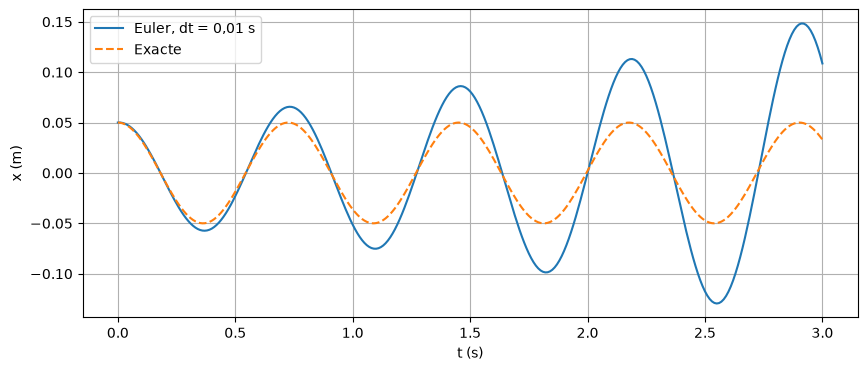

In [39]:
t, etats = euler(pentes, [x0, v0], 0.01, 3, k, m)
wt = omega * t
x_exact = x0 * np.cos(wt)

plt.figure(figsize=(10, 4))
plt.plot(t, etats[:, 0], label="Euler, dt = 0,01 s")
plt.plot(t, x_exact, "--", label="Exacte")
plt.xlabel("t (s)")
plt.ylabel("x (m)")
plt.legend()
plt.grid(True)
plt.show()

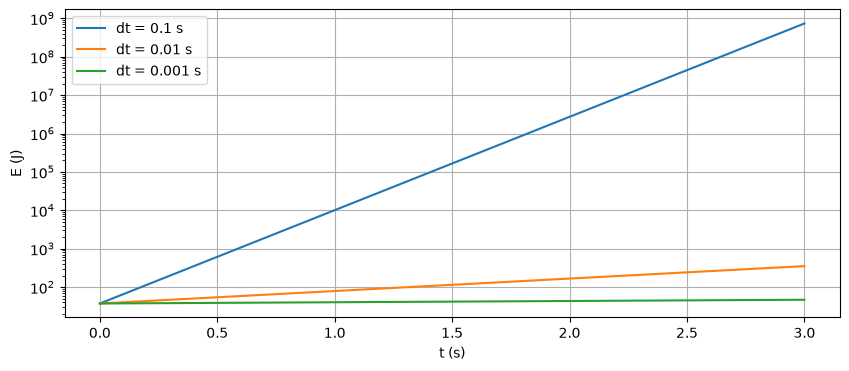

In [40]:
plt.figure(figsize=(10, 4))
for dt in [0.1, 0.01, 0.001]:
    t, etats = euler(pentes, [x0, v0], dt, 3, k, m)
    x = etats[:, 0]
    v = etats[:, 1]
    E = 1/2 * m * v**2 + 1/2 * k * x**2
    plt.plot(t, E, label=f"dt = {dt} s")

plt.yscale("log")
plt.xlabel("t (s)")
plt.ylabel("E (J)")
plt.legend()
plt.grid(True)
plt.show()

In [41]:
t_eval = np.linspace(0, 3, 1000)
sol = solve_ivp(pentes, (0, 3), [x0, v0], t_eval=t_eval, args=(k, m))
x_exact = x0 * np.cos(omega * sol.t)

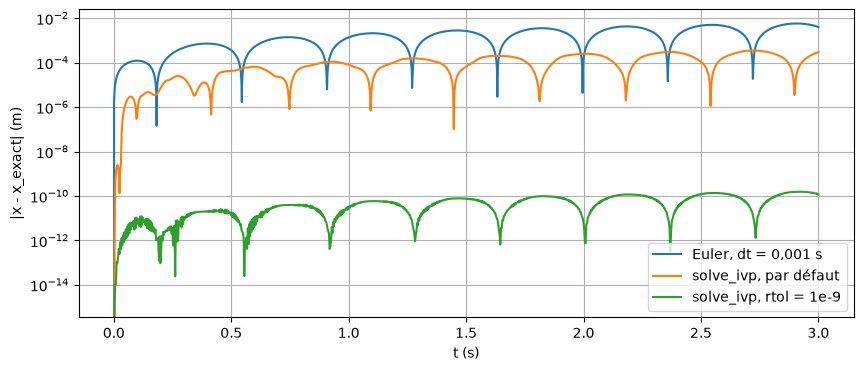

Euler          : 3000 appels | erreur max : 0.005754893912785809
RK45 défaut    : 182 appels | erreur max : 0.0003520286248368497
RK45 précis    : 3170 appels | erreur max : 1.5593318303253056e-10


In [ ]:
# --- 1. solve_ivp avec les réglages par défaut (méthode RK45) ---
t_eval = np.linspace(0, 3, 1000)
sol_def = solve_ivp(pentes, (0, 3), [x0, v0], t_eval=t_eval, args=(k, m))

# --- 2. solve_ivp avec une tolérance très stricte ---
sol_prec = solve_ivp(pentes, (0, 3), [x0, v0], t_eval=t_eval, args=(k, m),
                     rtol=1e-9, atol=1e-12)

# --- 3. Euler avec dt = 0,001 s ---
t_eu, etats_eu = euler(pentes, [x0, v0], 0.001, 3, k, m)

# --- Erreurs par rapport à la solution exacte ---
err_def  = np.abs(sol_def.y[0]  - x0 * np.cos(omega * sol_def.t))
err_prec = np.abs(sol_prec.y[0] - x0 * np.cos(omega * sol_prec.t))
err_eu   = np.abs(etats_eu[:, 0] - x0 * np.cos(omega * t_eu))

# --- Tracé ---
plt.figure(figsize=(10, 4))
plt.plot(t_eu, err_eu, label="Euler, dt = 0,001 s")
plt.plot(sol_def.t, err_def, label="solve_ivp, par défaut")
plt.plot(sol_prec.t, err_prec, label="solve_ivp, rtol = 1e-9")
plt.yscale("log")
plt.xlabel("t (s)")
plt.ylabel("|x - x_exact| (m)")
plt.legend()
plt.grid(True)
plt.show()

# --- Coût : nombre d'appels à la fonction pentes ---
print("Euler          :", len(t_eu) - 1, "appels | erreur max :", err_eu.max())
print("RK45 défaut    :", sol_def.nfev, "appels | erreur max :", err_def.max())
print("RK45 précis    :", sol_prec.nfev, "appels | erreur max :", err_prec.max())